In [1]:
import calcula_coeficientes as calc
import numpy as np
import matplotlib.pyplot as plt
import math as m

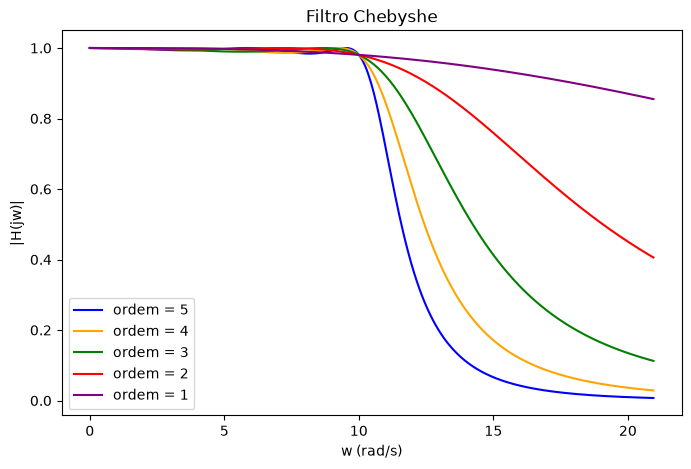

In [2]:
title = "Filtro Chebyshe"
xlable = "w (rad/s)"
ylable = "|H(jw)|"
texto = "ordem = "
arredondamento = 0

Habs_vector = []
list_plot = []

wc = 10
e = 0.2
nT = np.arange(1,6,1)
w = np.arange(0, 21, 0.05)


for n in nT:
    Habs_vector.append(calc.resposta_frequenciua(w,wc,n,e))
    
calc.grafico(w,Habs_vector,nT,title,xlable,ylable,texto,arredondamento)


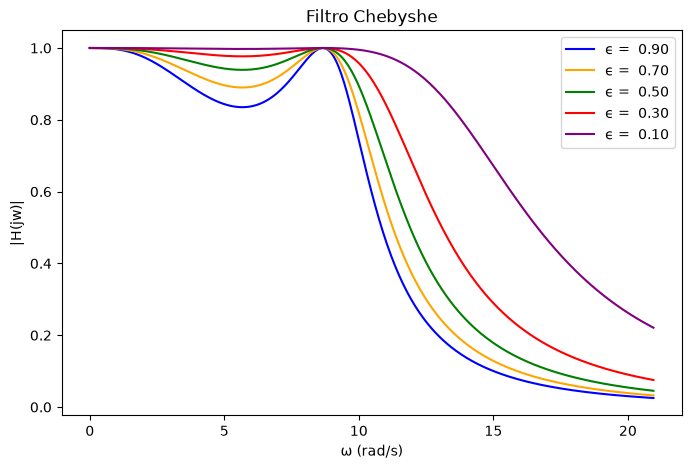

In [3]:
title = "Filtro Chebyshe"
arredondamento = 2
texto = "\u03F5 =  "


Habs_vector = []
list_plot = []

wc = 10
n = 3
w = np.arange(0, 21, 0.05)
e = np.arange(0.1,1,0.2)


for et in e:
    Habs_vector.append(calc.resposta_frequenciua(w,wc,n,et))

calc.grafico(w,Habs_vector,e,title,texto = texto,arredondamento = arredondamento)



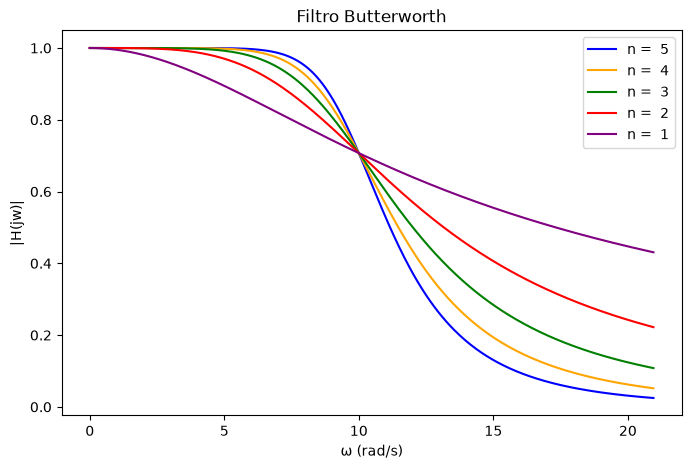

In [14]:
title = "Filtro Butterworth"
arredondamento = 0
texto = "n =  "

Habs_vector = []
list_plot = []

wc = 10
nT = np.arange(1,6,1)
w = np.arange(0, 21, 0.05)

for n in nT:
    Habs_vector.append(calc.resposta_frequenciua_Butterworth(w,wc,n))
    
calc.grafico(w,Habs_vector,nT, title,texto = texto,arredondamento = arredondamento)


In [5]:
c=['coisa',"foda"]
type(c[0])

str

In [6]:
def transformada(w):
    return (tal*m.sin(w*tal/2)/(w*tal/2))

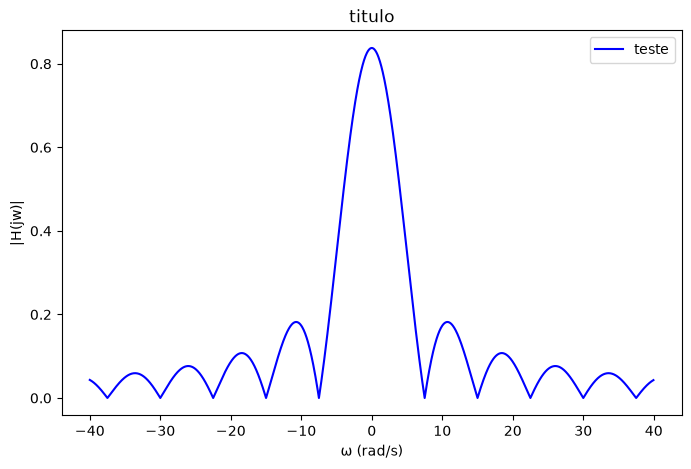

In [12]:
wm = 7.5
tal = 2*m.pi/wm
w = np.arange(-40,40,0.05)
Xjw = []
Xjw_m = []
Habs_vector = []

for w_ in w:
    if(w_==0):
        Xjw.append(tal)
        Xjw_m.append(tal)

    else:
        Xjw.append(transformada(w_))
        Xjw_m.append(abs(transformada(w_)))
curvas = ["teste"]
Habs_vector.append(Xjw_m)
calc.grafico(w,Habs_vector,curvas)


In [8]:
def filtro(W,wc):
    if(abs(W)<wc):
        Hxj = 1
    else:
        Hxj = 0
    return Hxj

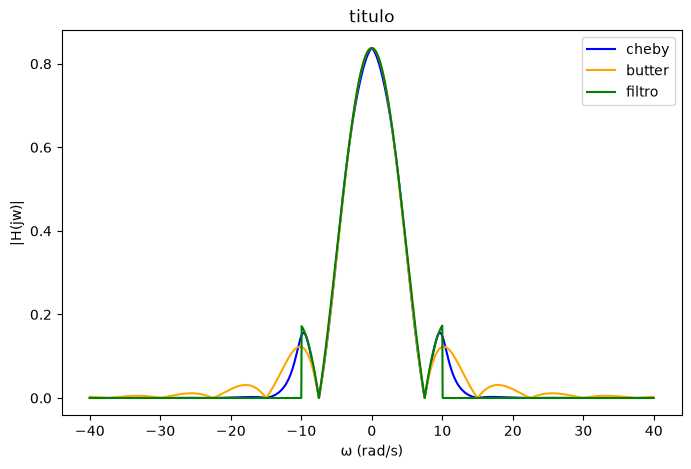

In [9]:
H  = []
Hb = []
Hc = []
Habs_vector = []
wc = 10
e = 0.6
nc = 4
nb = 2

curvas = ["filtro", "butter", "cheby"]

for i in range(0,len(Xjw),1):
    H.append(Xjw_m[i]*filtro(w[i],wc)) 
    Hb.append(Xjw_m[i]*calc.resposta_frequenciua_Butterworth(w,wc,nb)[i])    
    Hc.append(Xjw_m[i]*calc.resposta_frequenciua(w,wc,nc,e)[i])

Habs_vector.append(H)
Habs_vector.append(Hb)
Habs_vector.append(Hc)


calc.grafico(w,Habs_vector,curvas)



In [10]:
curvas = [1]
curvas[0] = 0
type(curvas[0])

int

In [11]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
fig = make_subplots(rows=1, cols=1,column_widths=[40])
list_plot = []

for i in range(0,len(Habs_vector)):

    fig.add_trace(go.Scatter(
        x=w,
        y=Habs_vector[i],
        mode= 'lines',
        visible=True,
        #hovertemplate=f"<br>Ordem ={i+1}<br>" +"</b> </b>|H(jw)|=</b> %{y}<br> ",
        hovertemplate="</b> </b>|H(jw)|=</b> %{y:.4f}<br> ",
        name= str(i+1) + " ordem" ,
    ),
        row=1, col=1)


fig.update_layout ( 
    hovermode = 'x unified', 
    hoversort="value descending",
    hoverdistance = 2,
    #hovermode = 'x unified',
    font_family= "Computer Modern Math Italic",
    xaxis_title_text="\u03C9 (rad/s)",  # Add label for x-axis in 1st subplot
    yaxis_title_text="|H(jw)|",
    
    ),
fig.update_layout(
    hoverlabel=dict(
        font_weight= 5,
        font_size=12,
        font_family= "Computer Modern Math Italic",
        
    ),    
)

fig.update_layout(height=600, width=800, title_text="Side By Side Subplots")
fig.show()